# 750-epoch sky map, the Earth-trailing-cloud test, and poster v6 (Oct 18, 2026)

All with the poster model: **Sun frame + sin/cos λ⊕** inputs (n·S n·z n·E n·vS n·vE n·x⊕ n·y⊕ sinλ⊕ cosλ⊕), 64-64-32-16
gelu MLP, mini-batch 512, one-cycle LR (peak 1e-3), **5 networks averaged**, corrected data (`ENV["ZODI_DATA"] = "z115"`),
on the **month-on/month-off splits** (30-day windows, shifted by 0, 10, …, 50 days; between-month windows for the map).

1. **Longer training**: the six month splits at 100 (round 16), 300 (round 20) and **750 epochs** (round 21, 30 trainings).
2. **The sky map with and without blending** (3.5° patches ≈ SPHEREx's view vs a 7° blend for display).
3. **The mentor's test: is the Earth-trailing cloud modelled well?** Stack Kelsall's trailing-cloud signal and the
   network's residuals along a geometric "am I looking through the cloud" axis.
4. **Poster v6**: every number and figure now from the 750-epoch runs.
5. **Overnight experiments (round 22)**: can dust-band inputs or a wider network fix the ecliptic stripe?

### Summary
* **750 epochs**: sky-map median error **0.0159%** (300 ep: 0.0178%, 100 ep: 0.0246%), p95 0.063%, within 2° of the
  ecliptic 0.083%, above 60° 0.0125%. Diminishing returns (300 → 750: −11%). The poster's own split: median **0.018%**,
  p95 0.069%, **97.5%** within 0.1% (100 epochs: 0.026%, 0.10%, 94.8%).
* **Blending** to 7° patches calms the map for display; the per-pointing errors are unchanged.
* **The trailing cloud is learned**: both axes track Kelsall's cloud (correlation 0.93–0.94 with its share of the
  light), yet the residuals stay flat (±0.01–0.02%) where a model missing just 1% of the cloud would show a ~0.06%
  trend. Fitted leftover fraction of the cloud: **0.06 ± 0.09%** near the plane, 0.09 ± 0.05% whole sky (750 epochs).
* The remaining structure was the **ecliptic stripe** (dust bands, ~0.08%), untouched by longer training.
* **Overnight (rounds 22–23): the round-9 dust-band inputs fix it.** On the poster's split the error within 2° of the
  ecliptic drops 3× (0.090% → 0.031%) at no cost elsewhere; a wider network alone does little; wider + bands is best on
  every measure (median 0.017%, p95 0.058%) but trains ~1.8× slower. On all six month splits (300 epochs + bands):
  sky-map median 0.0165%, p95 0.060%, **ecliptic 0.034%** (750-epoch poster model: 0.083%). The poster still uses the
  750-epoch model without bands (to be decided).


In [11]:
ENV["ZODI_DATA"] = "z115"
include(joinpath(@__DIR__, "..", "zodi_setup.jl"))
for f in ("mb_train.jl", "extra_features.jl", "summary_helpers.jl", "configs_v16.jl", "shift_helpers.jl",
          "r17_20_helpers.jl", "r21_22_helpers.jl")
    include(joinpath(@__DIR__, "..", "sweeps", f))
end


  Activating project at `c:\JuliaProjects\More_zodi`


target data: z115  (zodipy115_5um_boresight.h5);  results dir: sweeps\results_z115
description: Zodiacal light for SPHEREx pointing directions, regenerated with ZodiPy
wavelength:  5.0 micron
units:       MJy/sr
N = 423607 exposures;  emission range = (0.32295323811551996, 1.1021098132583944)
n·n     median  1.000e+00   iqr  0.000e+00
n·S     median  4.851e-03   iqr  3.475e-01
n·z     median  9.747e-03   iqr  1.361e+00
n·E     median  4.805e-03   iqr  3.475e-01
n·vS    median  1.615e-02   iqr  1.356e+00
n·vE    median  3.680e-02   iqr  1.383e+00
n·J     median -5.953e-02   iqr  2.659e+00
n·x     median  5.145e-02   iqr  8.549e-01
n·y     median -1.072e-03   iqr  5.523e-01
S·S     median  1.037e+00   iqr  1.341e-02
S·z     median  2.050e-04   iqr  6.195e-05
S·E     median  1.037e+00   iqr  1.341e-02
S·vS    median -1.048e-02   iqr  5.980e-02
S·vE    median -5.250e-03   iqr  2.289e-02
S·J     median -4.519e+00   iqr  1.400e+00
S·x     median  2.056e-01   iqr  1.095e+00
S·y     median -8.

## 1–2. The month splits at 100, 300 and 750 epochs, with and without blending
Out-of-sample error on the sky: every pointing is predicted by the versions that withheld its 30-day window
(between-month windows only), averaged. Top row: each pointing drawn as a 3.5° patch (≈ SPHEREx's field of view);
bottom row: blended over 7° patches (display only). Same colour scale everywhere.


┌ Warning: JSON-RPC endpoint has been blocked writing to its peer; outgoing messages are queueing up and will not be delivered until the peer resumes reading
│   blocked_seconds = 162.8
│   queued_messages = 0
└ @ VSCodeServer.JSONRPC c:\Users\marka\.vscode\extensions\julialang.language-julia-1.249.2\scripts\packages\JSONRPC\src\core.jl:414


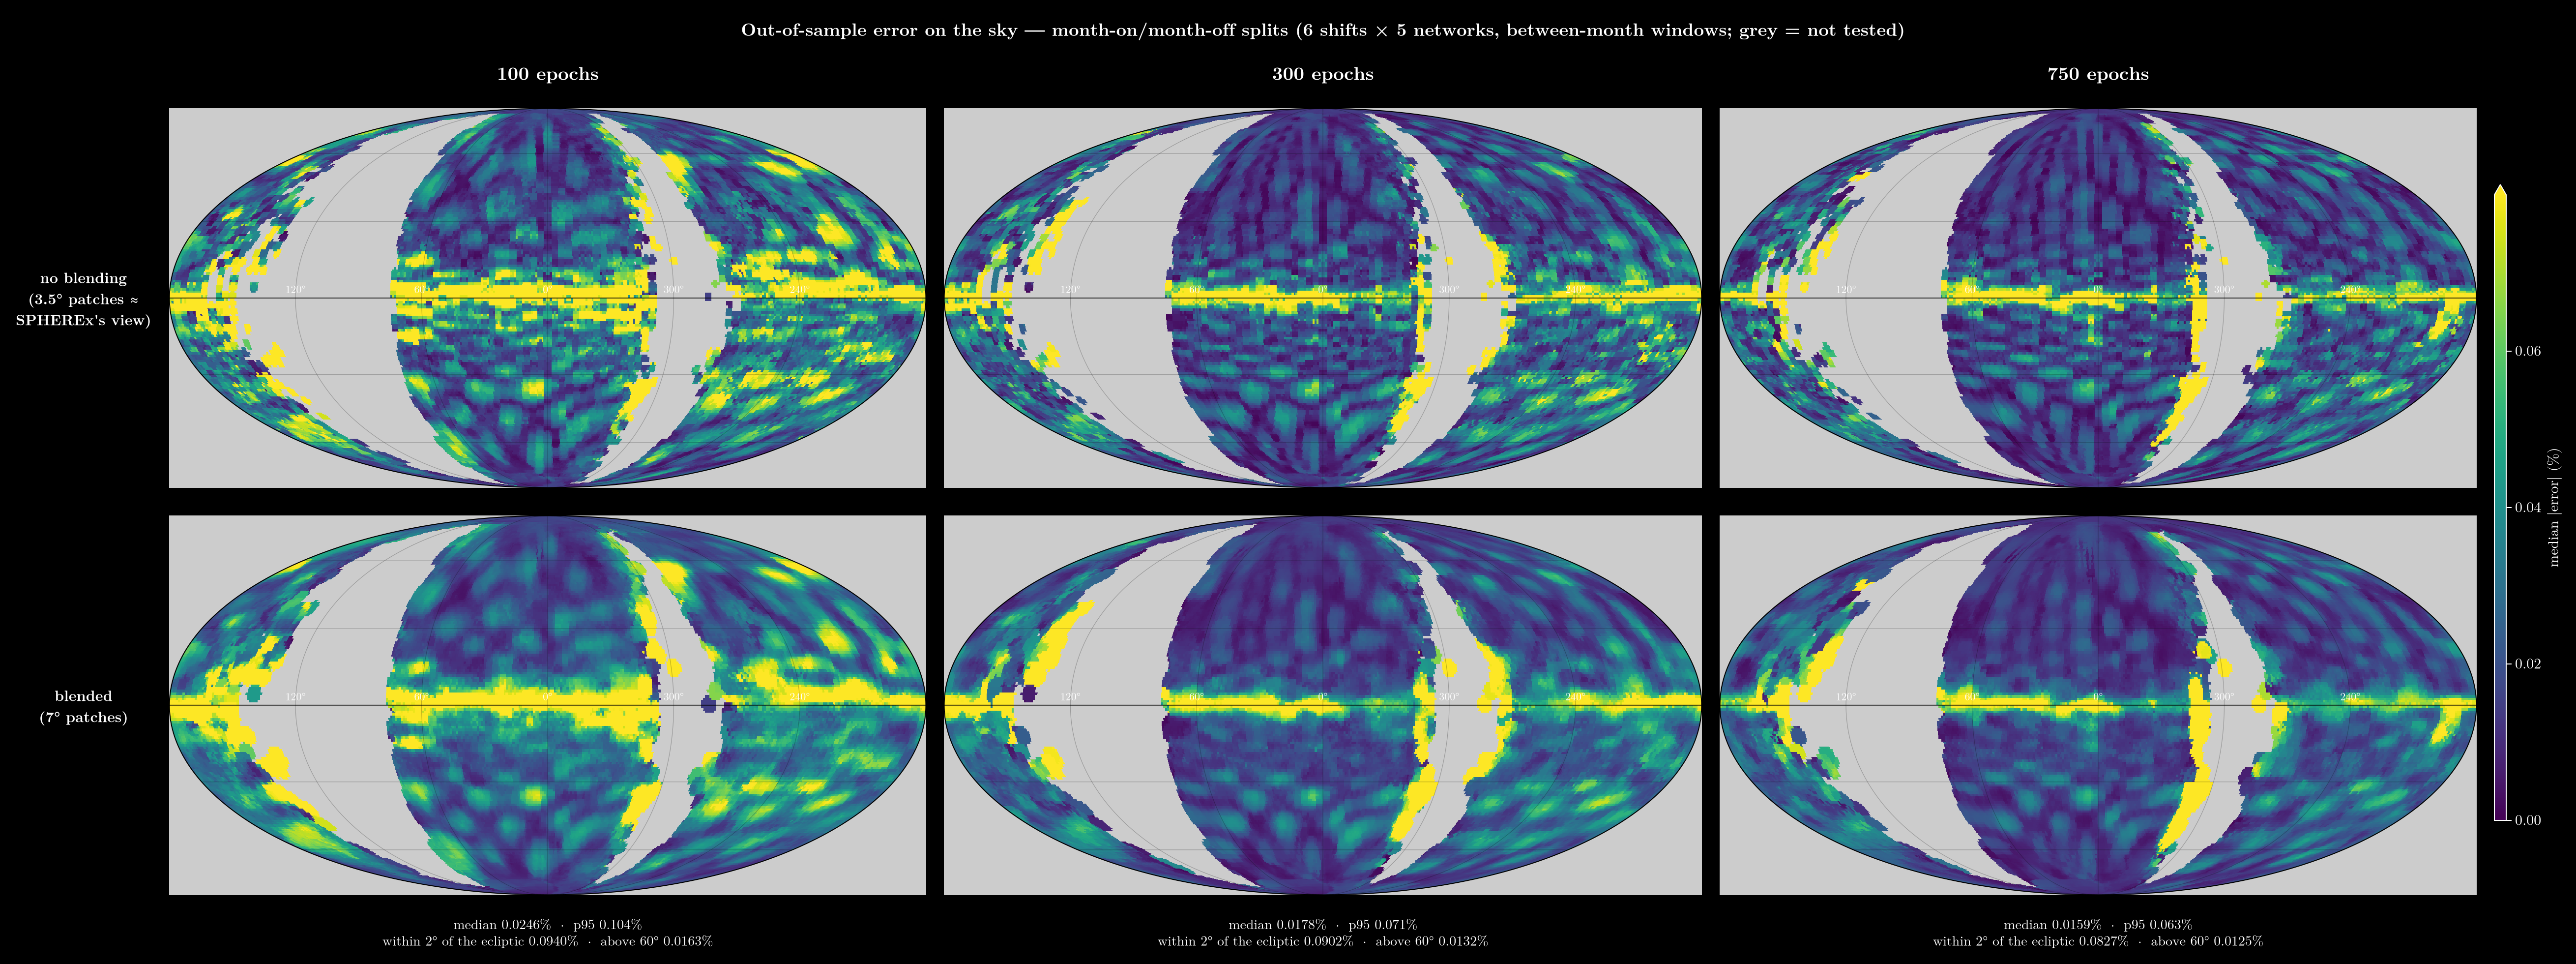

In [12]:
skymap_grid_fig()


Per shift, median |error| between months and (where present) at the mission's start/end:


In [13]:
m300_table(((fam100, 100), (fam300, 300), (fam750, 750)))


Row,shift_days,between_100ep,ends_100ep,between_300ep,ends_300ep,between_750ep,ends_750ep
,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,0,0.0263,NaN,0.0196,NaN,0.0183,NaN
2,10,0.0296,0.0373,0.0196,0.0196,0.018,0.0227
3,20,0.0372,0.2212,0.0327,0.1091,0.0303,0.0717
4,30,0.0348,0.1071,0.0287,0.0627,0.0275,0.0869
5,40,0.0257,0.0307,0.0185,0.0179,0.0177,0.0161
6,50,0.0227,NaN,0.0169,NaN,0.0149,NaN


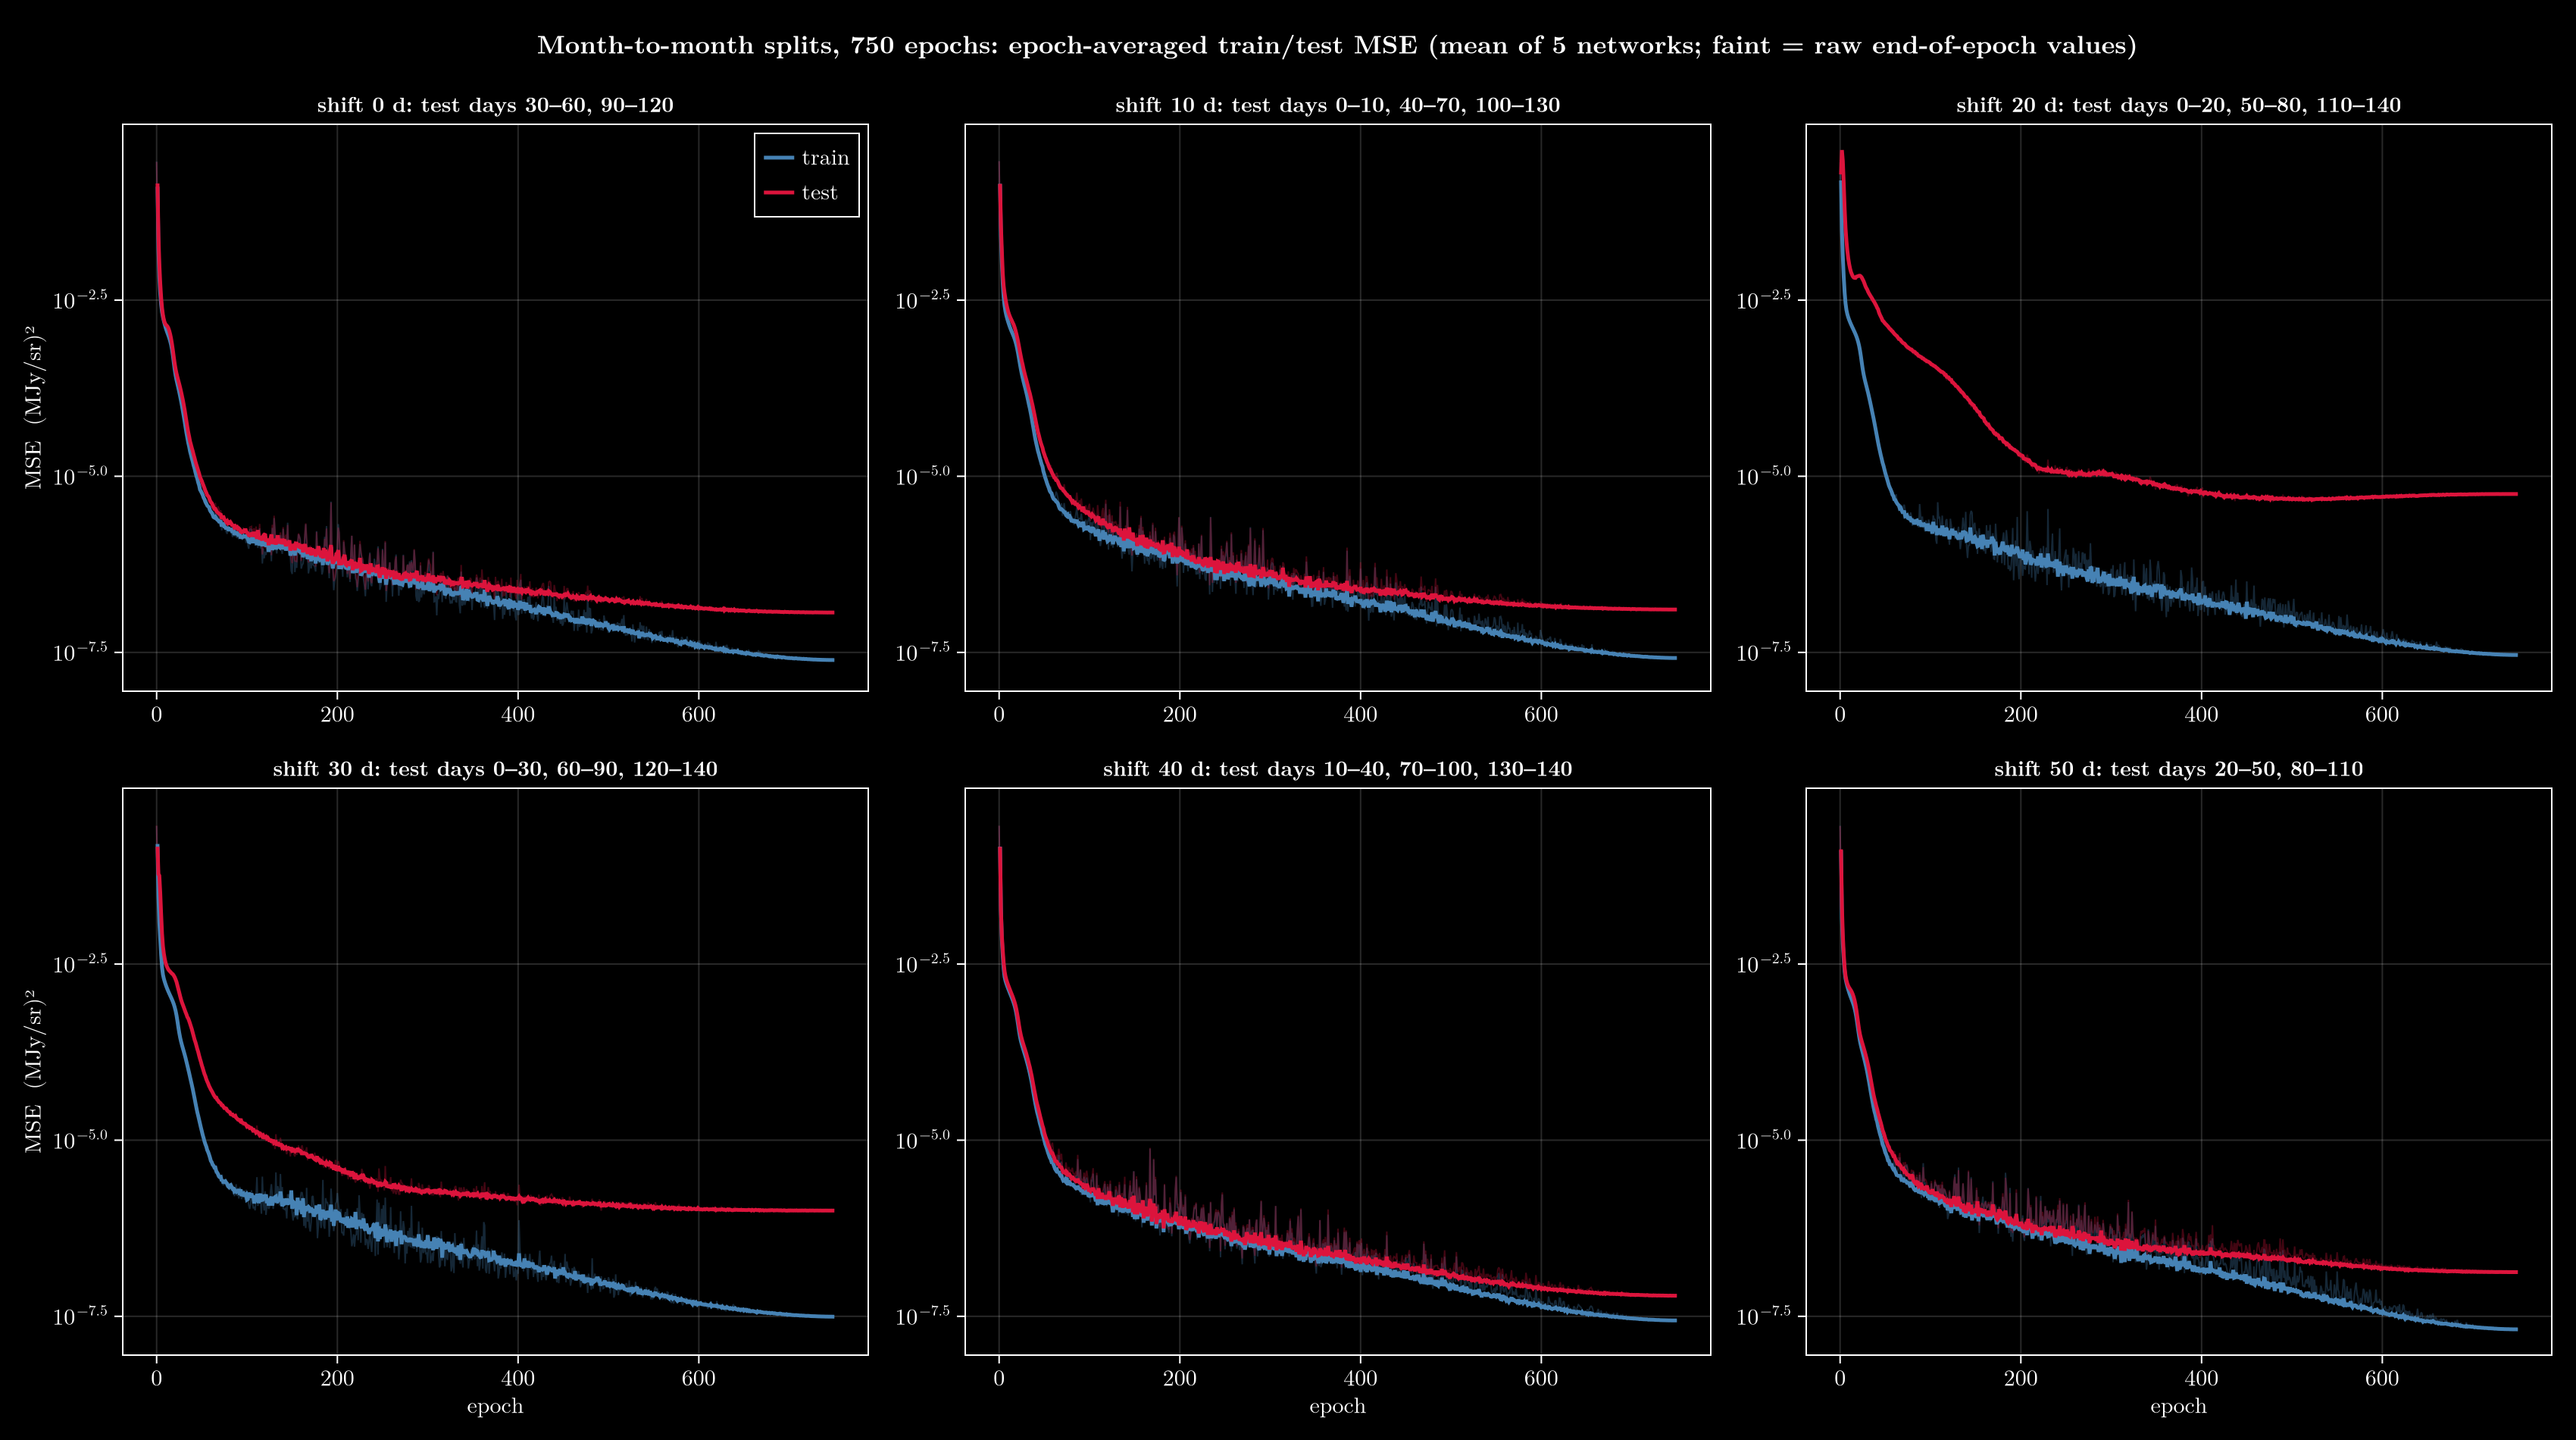

In [14]:
loss_m300_fig(fam750)


## 3 Is the Earth-trailing cloud modelled well?

Two x-axes, both built from dot products of the look direction n:
* **ahead vs behind Earth**: the angle between n and Earth's direction of motion v̂⊕ (0° = straight ahead,
  180° = straight behind). v̂⊕ is the in-plane basis vector that turns with Earth (≈ y⊕).
* **toward the cloud's centre**: the angle between n and the direction from SPHEREx to the centre of Kelsall's trailing
  blob (1.06 AU from the Sun, 10° behind Earth in its orbit). This also accounts for the blob sitting slightly inside
  Earth's orbit.

Angles rather than dot products, because SPHEREx looks ~90° from the Sun, so the dot products pile up near ±1.
Top: what Kelsall predicts (the trailing cloud's share of the light, from ZodiPy's per-component output). Bottom: the
network's residuals on pointings it never saw, and (dotted) what a model that missed 1% of the cloud would show.


correlation with the trailing cloud's share of the light: ahead/behind angle 0.930, angle to the cloud's centre -0.944


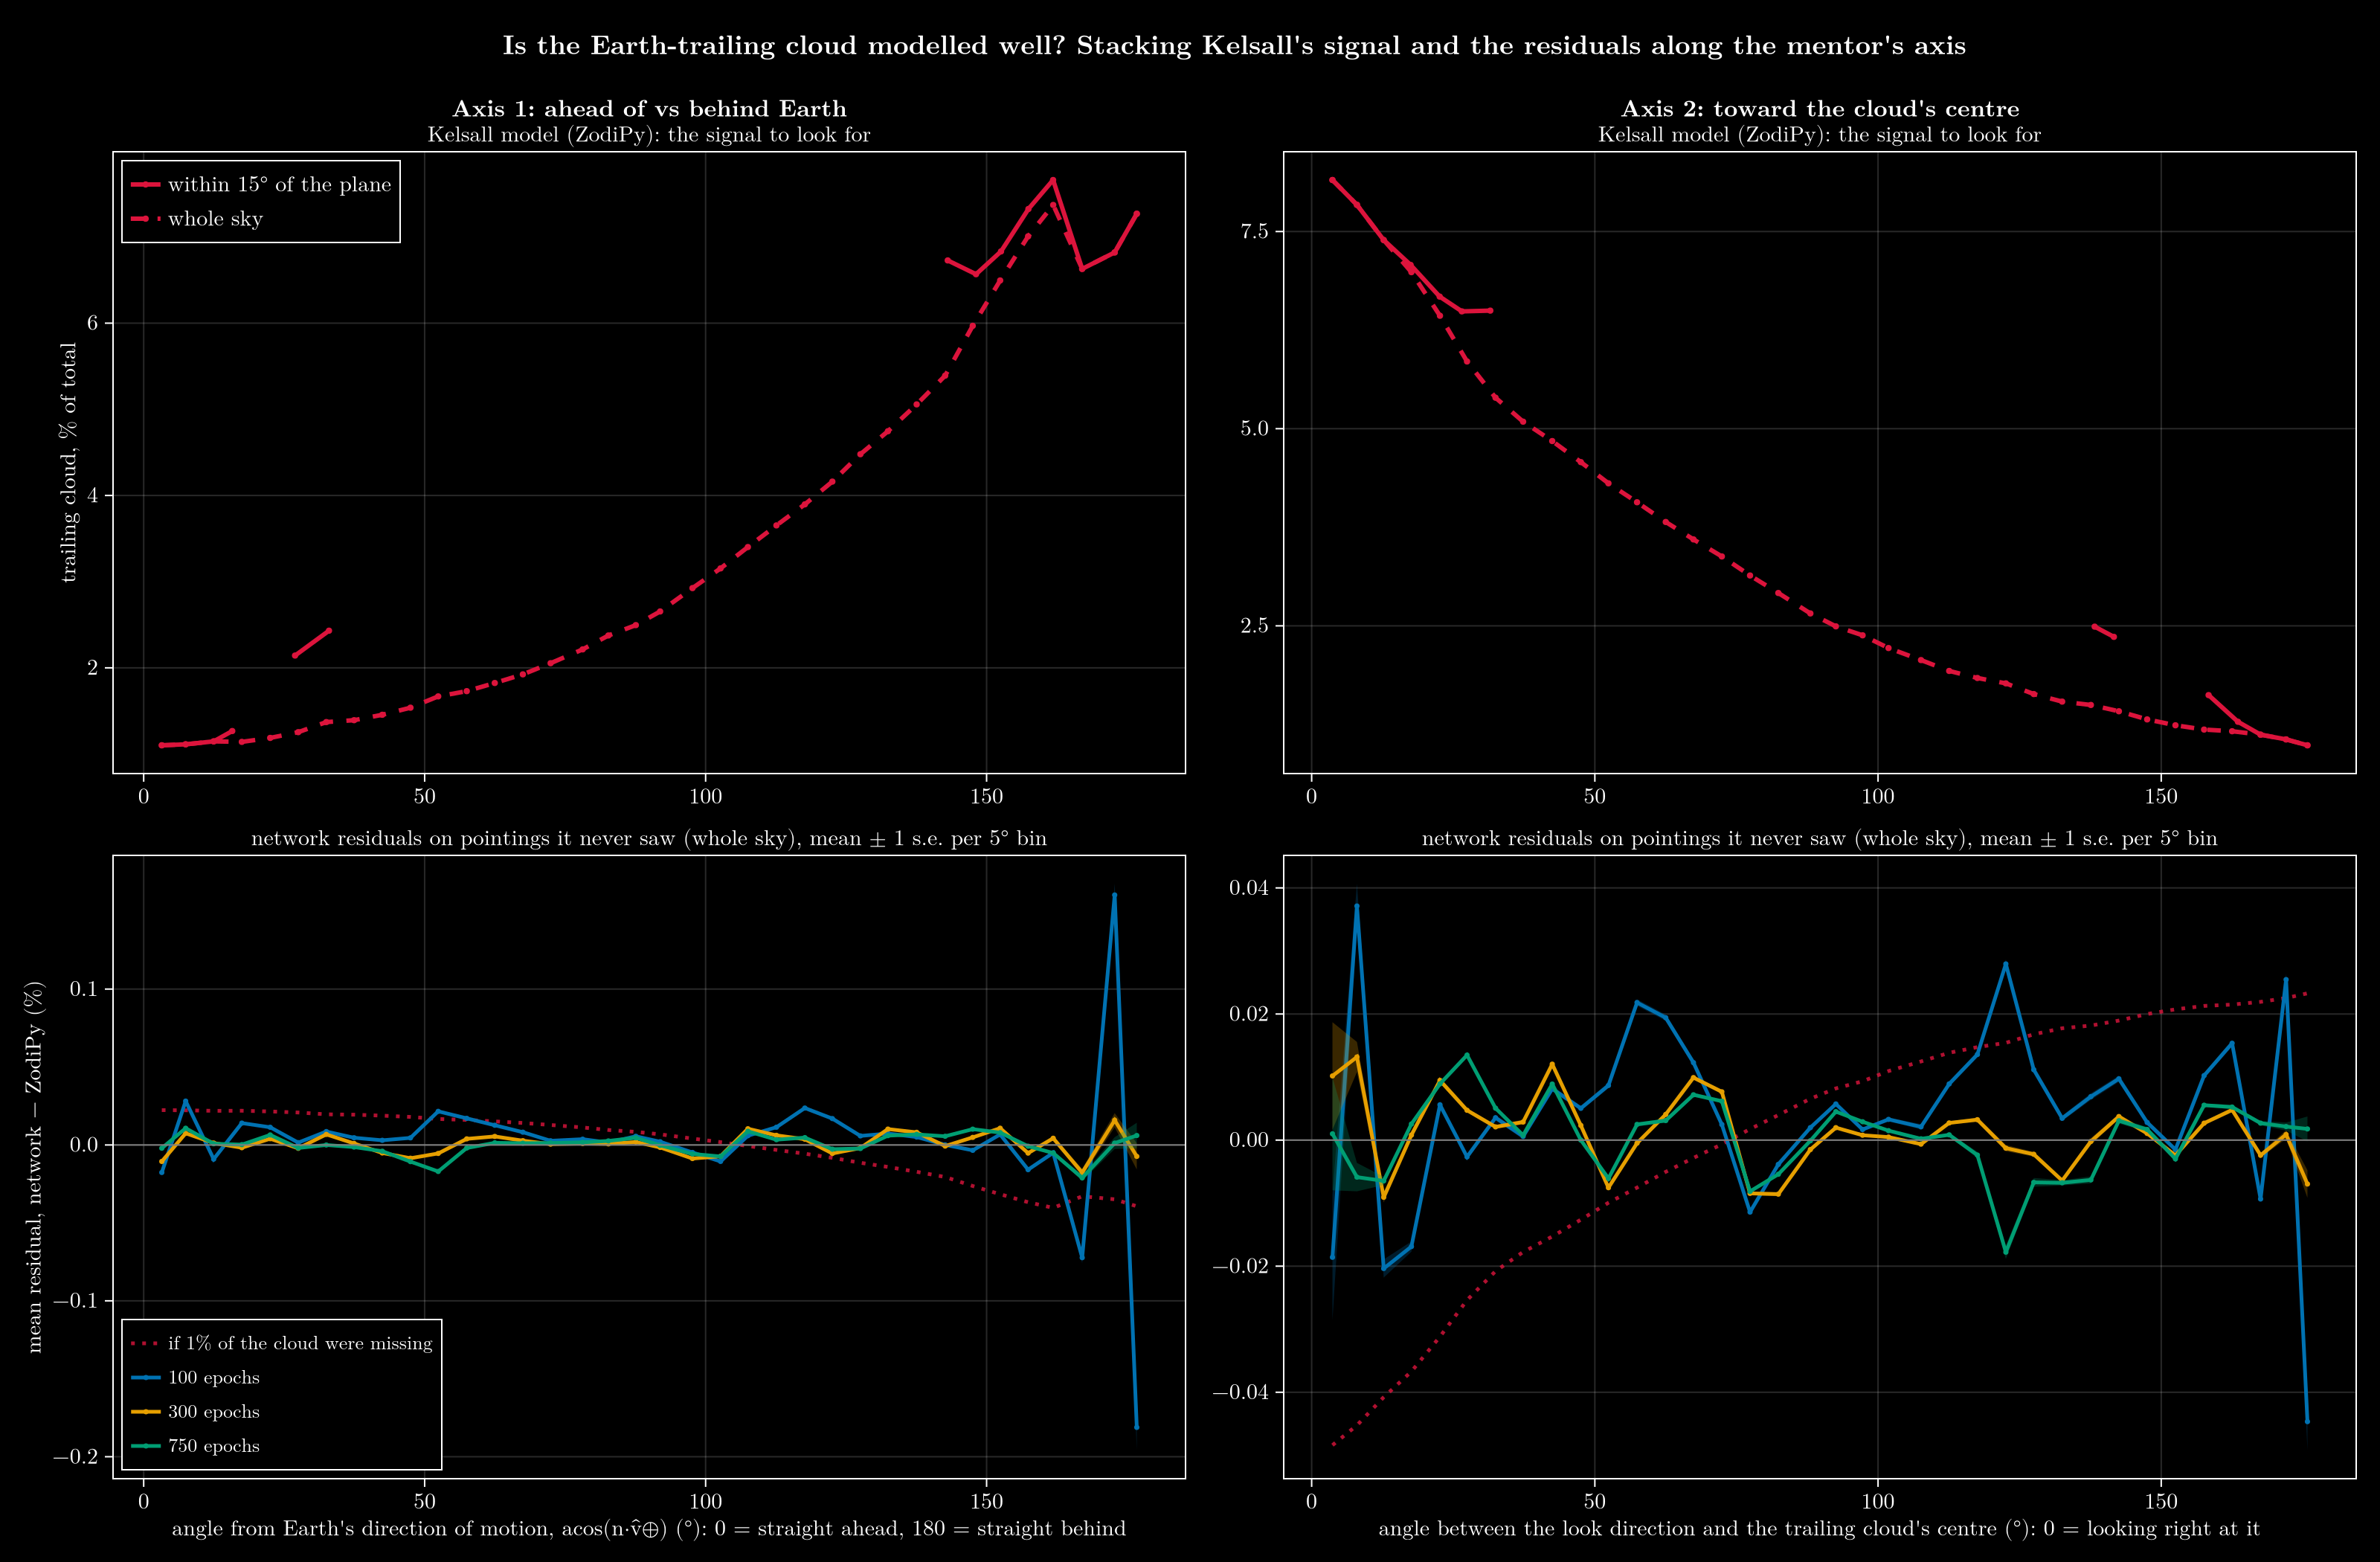

In [15]:
let a = trailing_axes(), ftf = 100 .* TF_EMISSION ./ y
    @printf("correlation with the trailing cloud's share of the light: ahead/behind angle %.3f, angle to the cloud's centre %.3f\n",
            cor(ftf, a.ahead), cor(ftf, a.blob))
end
TS_FIG, TS_TABLE = trailing_stack_fig()
TS_FIG


A direct number: fit residual = a·(trailing-cloud share, %) + b over all tested pointings. a = −1 would mean the cloud
is entirely missing from the network, 0 that it is perfectly reproduced; the uncertainty is the spread of a over the
5 individual networks.


In [16]:
TS_TABLE


Row,axis,epochs,region,missing_fraction,seed_std
,String,Int64,String,Float64,Float64
1,residual = a·(cloud %) + b,100,|β| < 15°,-0.0022,0.0018
2,residual = a·(cloud %) + b,100,whole sky,-0.0014,0.0017
3,residual = a·(cloud %) + b,300,|β| < 15°,-0.0001,0.0007
4,residual = a·(cloud %) + b,300,whole sky,0.0006,0.0005
5,residual = a·(cloud %) + b,750,|β| < 15°,0.0006,0.0009
6,residual = a·(cloud %) + b,750,whole sky,0.0009,0.0005


**The trailing cloud is learned**: the leftover fraction is consistent with zero (|a| ≲ 0.1–0.2% of the cloud's own
brightness at 300 and 750 epochs). The residual wiggles along the axes (±0.01–0.02%) do not follow the cloud's shape.
Near the plane the pointings sit only at the two ends of the ahead/behind axis (SPHEREx looks ~90° from the Sun), so
the whole-sky stack is used for the residuals.

## 4. Poster v6
Every number and figure now comes from the 750-epoch runs (`poster/data_*.jl`; the poster's split is shift 0):
banner ~0.02%; tiles 0.018% / 97.5% / ≤0.03%; Fig. 4 accuracy + 1:1 scatter; Fig. 5 epoch-averaged training curves;
Fig. 6 shift timeline (0.015–0.03% between months); Fig. 7 sky map (0.08% on the ecliptic, 0.013% near the poles),
in two versions (`poster_{light,dark}.pptx` = 7° blend, `poster_{light,dark}_35.pptx` = 3.5° patches).
New since v4: Fig. 2 (what makes up the zodiacal light), the 1:1 scatter, shorter bullet text.

## 5. Overnight: fixing the ecliptic stripe (round 22)
The stripe along the ecliptic (dust bands, ~0.08–0.09%) barely moved with longer training (section 1), so it is a
limit of the model's inputs or size, not of training time. Round 22 tries both, on the poster's split (shift 0),
300 epochs, 5 networks each, against the 300- and 750-epoch baselines:
* **+ dust bands**: the 3 sharp dust-band profiles of round 9 (`:sunseason_bandsharp`) added to the poster inputs;
* **wider net**: 128-128-64-32 (4× the parameters);
* **wider + bands**: both.


In [17]:
r22_table([("z115_m300_shift0", "baseline, 300 epochs"), ("z115_m750_shift0", "baseline, 750 epochs"),
           ("z115_r22_bands", "+ dust bands"), ("z115_r22_big", "wider net"), ("z115_r22_bigbands", "wider + bands")])


Row,arm,seeds,median_pct,p95_pct,ecl_lt2deg_pct,above60_pct,ens_test_mse,final_train_mse
,String,Int64,Float64,Float64,Float64,Float64,String,String
1,"baseline, 300 epochs",5,0.0196,0.074,0.0899,0.0156,6.59e-08,3.71e-08
2,"baseline, 750 epochs",5,0.0183,0.069,0.0798,0.0149,6.23e-08,2.48e-08
3,+ dust bands,5,0.0192,0.067,0.0308,0.0149,4.60e-08,1.85e-08
4,wider net,5,0.0188,0.069,0.0809,0.0147,6.05e-08,2.84e-08
5,wider + bands,5,0.0169,0.058,0.0288,0.0138,3.44e-08,1.16e-08


**The dust-band inputs fix the stripe**: within 2° of the ecliptic the error drops 3× (0.090% → 0.031%) with nothing
lost elsewhere (p95 and the test MSE improve too). Unlike round 9, where the same inputs hurt the 30-day-block test of
the older season model, here they help everywhere. The wider network alone does little; wider + bands is best on every
measure (median 0.017%, p95 0.058%, ecliptic 0.029%) but trains ~1.8× slower.

## 6. The dust-band model on all six month splits (round 23)
The round-22 "+ dust bands" model on the other five shifted splits (25 trainings), for the out-of-sample sky map.
Compared with the poster's 750-epoch model, same drawing and colour scale.


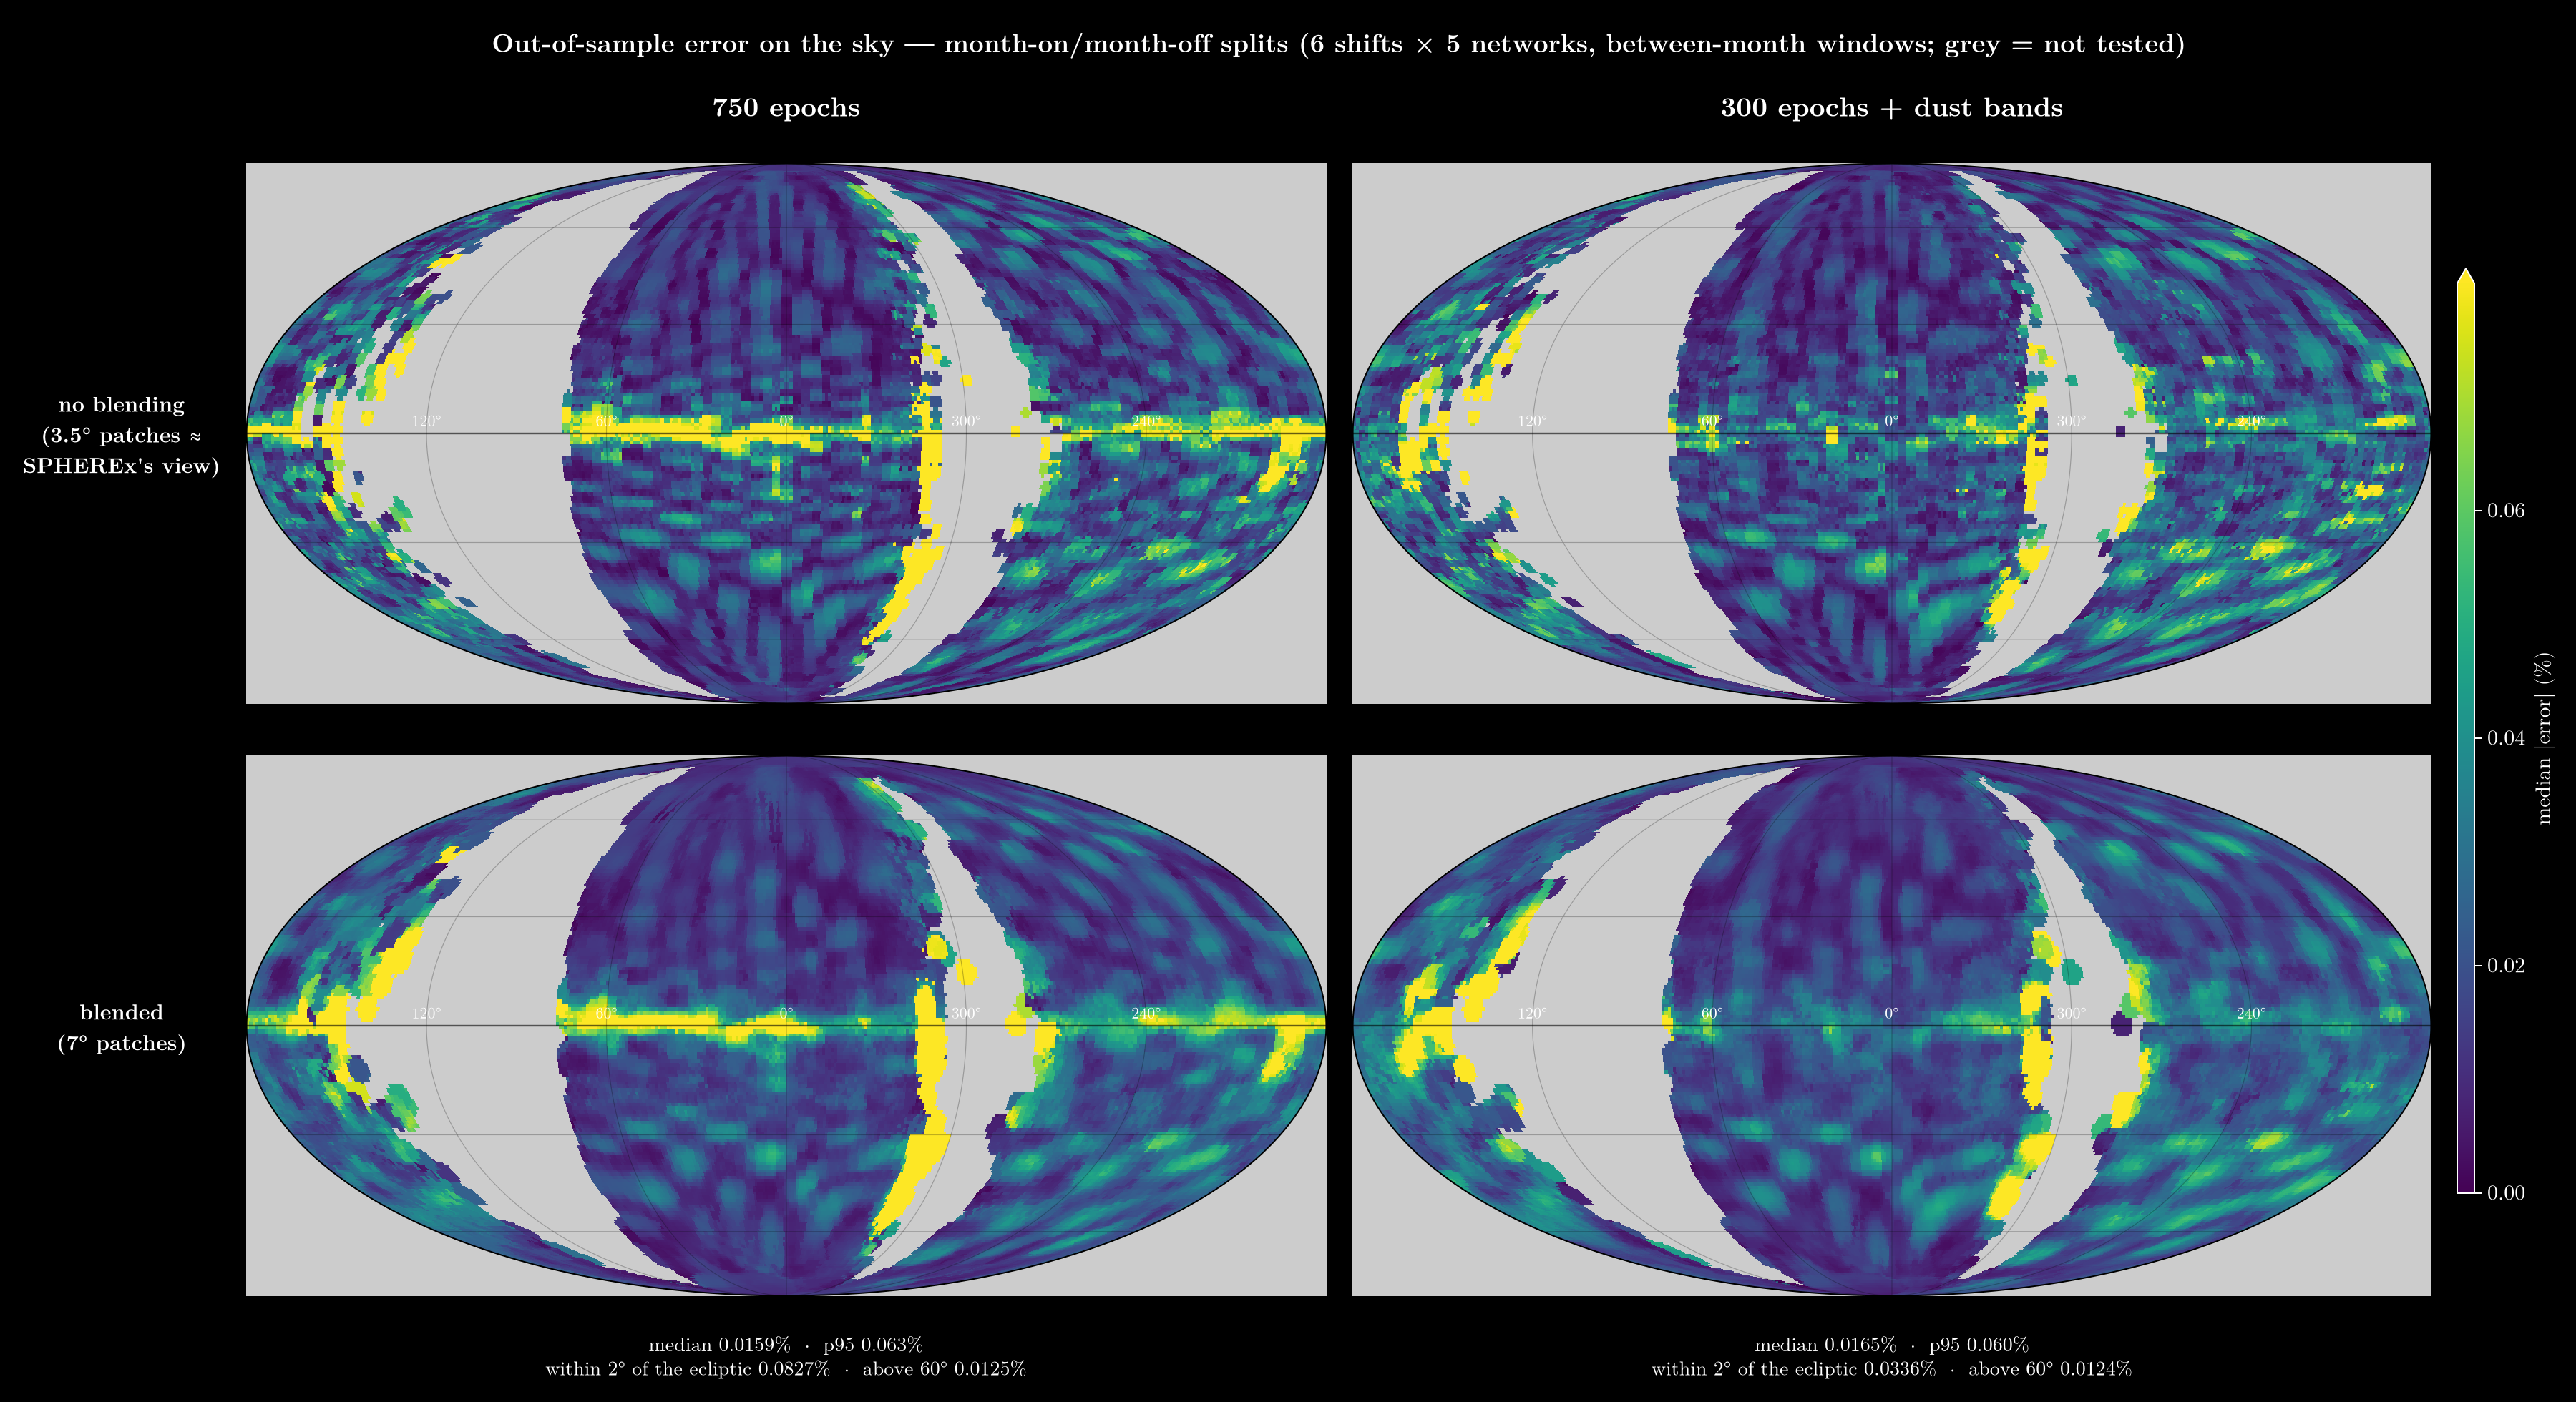

In [18]:
skymap_grid_fig(((fam750, "750 epochs"), (famB, "300 epochs + dust bands")))


In [19]:
let (E7, EB) = (oos_interior(fam750), oos_interior(famB)), S7 = sky_stats(E7), SB = sky_stats(EB)
    DataFrame(model=["poster model, 750 epochs", "+ dust bands, 300 epochs"], exposures=[S7.n, SB.n],
              median_pct=round.([S7.med, SB.med], digits=4), p95_pct=round.([S7.p95, SB.p95], digits=3),
              ecliptic_lt2deg_pct=round.([S7.ecl, SB.ecl], digits=4), above60deg_pct=round.([S7.pole, SB.pole], digits=4))
end


Row,model,exposures,median_pct,p95_pct,ecliptic_lt2deg_pct,above60deg_pct
,String,Int64,Float64,Float64,Float64,Float64
1,"poster model, 750 epochs",364797,0.0159,0.063,0.0827,0.0125
2,"+ dust bands, 300 epochs",364797,0.0165,0.06,0.0336,0.0124
